# Add Dimensions to PHyDAP Runoff Data

## Contents
- [Input Datasets for this Notebook](#input-datasets-for-this-notebook)
- [0. Import required modules](#0-import-required-modules)
- [1. Organize data folders and files](#1-organize-data-folders-and-files)
    - [1.1 Create "Runoff" subfolder](#11-create-runoff-subfolder)
    - [1.2 Create subfolders in "Runoff" subfolder ("Raw", "Interim", "Processed")](#12-create-subfolders-in-runoff-subfolder-raw-interim-processed)
    - [1.3 Move input data files to "Raw" subfolder](#13-move-input-data-files-to-raw-subfolder)
- [2. Declare relevant variables (input/output file paths, field names etc.)](#2-declare-relevant-variables-inputoutput-file-paths-field-names-etc)
- [3. Add dimension to PHyDAP raw .nc file](#3-add-dimension-to-phydap-raw-nc-file)
    - [3.1 Extract data from phydap raw file](#31-extract-data-from-phydap-raw-file)
    - [3.2 Specify the basins of interest (option to use HYBAS_ID or indices)](#32-specify-the-basins-of-interest-option-to-use-hybas_id-or-indices)
    - [3.3 Generate new .nc file with latitude dimension](#33-generate-new-nc-file-with-latitude-dimension)
    - [3.4 Quality Check - Ensure that the netCDF file retains shape (no shuffling of data)](#34-quality-check---ensure-that-the-netcdf-file-retains-shape-no-shuffling-of-data)
- [4. Generate GridWeights.txt file from PHyDAP shapefile](#4-generate-gridweightstxt-file-from-phydap-shapefile)
    - [4.1 Load data from hydrofabric and PHyDAP shapefiles](#41-load-data-from-hydrofabric-and-phydap-shapefiles)
    - [4.2 Map PHyDAP to hydrofabric subbasin IDs](#42-map-phydap-to-hydrofabric-subbasin-ids)
    - [4.3 Generate and output GridWeights.txt file](#43-generate-and-output-gridweightstxt-file)
- [5. Time offsets](#5-time-offsets)



## Input Datasets for this Notebook

Prior to running this notebook, ```0_depression_depths_calc.ipynb``` must be ran first. Then, the following files must be downloaded and pasted into the "Data" folder at the root project directory:

- ```PHyDAP_era5_hourly_upland_runoff.nc``` from the [FRDR website](https://www.frdr-dfdr.ca/repo/dataset/7ce4bd7a-4bcc-4f8c-8129-32a691f46c8e)
- [PHyDAP Prairie Hydrosheds shapefile](https://www.frdr-dfdr.ca/repo/dataset/7ce4bd7a-4bcc-4f8c-8129-32a691f46c8e) (paste all files inside the zip Version_02 > metadata > PrairieHydroshedsShapefile.zip)



## 0. Import required modules

In [1]:
# System
import os
from pathlib import Path
import shutil
import sys
from netCDF4 import Dataset

# Ensure PWA directory is in the system path
prj_path = os.path.abspath(os.path.join(os.getcwd(), '..'))
if prj_path not in sys.path:
    sys.path.insert(0, prj_path)

# Analysis
from netCDF4 import Dataset
import numpy as np
import pandas as pd
import geopandas as gpd

# Custom Libraries
import src.py.phydap as phydap
from src.py.ui import *

# Visualization
import matplotlib.pyplot as plt

In [2]:
data_cat = usr_input().string(description = 'data category (Runoff (r), snowmelt (s), rainfall(p))', default_value='r')

## 1. Organize data folders and files

### 1.1 Create "Runoff" subfolder

In [3]:
# Set watershed name
WATERSHED_NAME = usr_input().string("watershed name", default_value='manning')


# Path for this notebook
NOTEBOOK_PATH = Path.cwd()


# Path for PWA root
PWA_PATH = str(NOTEBOOK_PATH.parent.as_posix())


# Path for base raw data folder
BS_DATA_PATH = PWA_PATH + r"/Data/"


# Specify path for watershed folder
WATERSHED_PATH = BS_DATA_PATH + WATERSHED_NAME


# Path for Runoff folder
if data_cat.lower() == 'r':
    FOLDER_PATH = WATERSHED_PATH + r"/Runoff"
elif data_cat.lower() == 's':
    FOLDER_PATH = WATERSHED_PATH + r"/Snowmelt"
elif data_cat.lower() == 'p':
    FOLDER_PATH = WATERSHED_PATH + r"/Rainfall"
else:
    raise ValueError("Invalid data category. Please enter 'r', 's', or 'p'.")


# Create watershed folder in specified path
os.makedirs(FOLDER_PATH, 
            exist_ok=True) # Do nothing if already exists

### 1.2 Create subfolders in "Runoff" subfolder ("Raw", "Interim", "Processed")

In [4]:
# Specify paths for depression depths subfolders
NC_RAW_PATH = FOLDER_PATH + r"/Raw/"
NC_INTERIM_PATH = FOLDER_PATH + r"/Interim/"
NC_PROCESSED_PATH = FOLDER_PATH + r"/Processed/"


# Create watershed subfolders in specified paths
SUBFOLDERS_LIST = [NC_RAW_PATH,
                   NC_INTERIM_PATH,
                   NC_PROCESSED_PATH]
for sub in SUBFOLDERS_LIST:
    os.makedirs(sub, exist_ok=True)

### 1.3 Move input data files to "Raw" subfolder

In [5]:
# Specify source and destination folders before moving files
src = Path(BS_DATA_PATH)
dst = Path(NC_RAW_PATH)


# Move files in base data folder to watershed folder
for file in src.iterdir():
     if file.is_file():
        destination_file = dst / file.name
        if destination_file.exists():
            print(f"Skipped (already exists): {file.name}")
            continue
        shutil.move(str(file), destination_file)

In [6]:
# Depression depths shapefile name (generated in depression_depths_calc.ipynb)
DEPRESSION_DEPTHS_SHAPEFILE = usr_input().string('depression depths shapefile name (without extension, output file from 0_ notebook): ', default_value='CLRH_basins_depression_depths')

# Depression depths shapefile path
DEPRESSION_DEPTHS_PATH = WATERSHED_PATH + r"/HydroConditioning/Processed"

# Copy and paste depression depths files to "Raw" folder
for filename in os.listdir(DEPRESSION_DEPTHS_PATH):
    print(filename)
    if filename.startswith(DEPRESSION_DEPTHS_SHAPEFILE):
        print("Copying:", filename)
        source_path = os.path.join(DEPRESSION_DEPTHS_PATH, filename)
        destination_path = os.path.join(NC_RAW_PATH, filename)
        if os.path.isfile(source_path):  # Avoid copying directories
            shutil.copy2(source_path, destination_path)  # copy2 preserves metadata

No depression depths shapefile name (without extension, output file from 0_ notebook):  provided. Default applied ('CLRH_basins_depression_depths').
CLRH_basins_depression_depths.cpg
Copying: CLRH_basins_depression_depths.cpg
CLRH_basins_depression_depths.dbf
Copying: CLRH_basins_depression_depths.dbf
CLRH_basins_depression_depths.prj
Copying: CLRH_basins_depression_depths.prj
CLRH_basins_depression_depths.shp
Copying: CLRH_basins_depression_depths.shp
CLRH_basins_depression_depths.shx
Copying: CLRH_basins_depression_depths.shx
merged_average_dem_filled_clip_resample_5m_FillBurn_Deps_Corr.tif.crdownload
Wetlands_Polygons_with_Stats.cpg
Wetlands_Polygons_with_Stats.dbf
Wetlands_Polygons_with_Stats.prj
Wetlands_Polygons_with_Stats.shp
Wetlands_Polygons_with_Stats.shx
Wetlands_Stats.csv
ZonalStats_upper_pembina.html


## 2. Declare relevant variables (input/output file paths, field names etc.)

In [7]:
# Variables for the netCDF file
path_out = NC_PROCESSED_PATH
var_units = "mm/h"
dim1_name = "time_hrs"
dim2_name = "HYBAS_ID"

# Output path for the GridWeights.txt file
path_out_grid = NC_PROCESSED_PATH + "GridWeights.txt"

In [8]:
PHYDAP_RAW = f"../Data/{WATERSHED_NAME}/Runoff/Raw/"

# Function inputs (eventually will become a function) - netCDF
nc_file_path = PHYDAP_RAW + usr_input().string('input netCDF file name', default_value='PHyDAP_RDRS21_hourly_runoff') + ".nc"

# Input file path for the PHyDAP shapefile
path_in_phydap_shp = PHYDAP_RAW + usr_input().string('Enter the PHyDAP shapefile name (without .shp extension)', default_value='prairie_hydrosheds_true_WGS84') + ".shp"

# Input file path for the depression depths shapefile
path_in_deps_shp = NC_RAW_PATH + DEPRESSION_DEPTHS_SHAPEFILE

No input netCDF file name provided. Default applied ('PHyDAP_RDRS21_hourly_runoff').
No Enter the PHyDAP shapefile name (without .shp extension) provided. Default applied ('prairie_hydrosheds_true_WGS84').


### Pre-flight file check

In [9]:
# Pre-flight check: Verify all input files exist in NC_RAW_PATH
print(f"Checking for files in: {NC_RAW_PATH}\n")

# List of expected files from usr_input() calls
expected_files = {
    'NetCDF file': f"{nc_file_path.replace(NC_RAW_PATH, '')}",
    'PHyDAP shapefile': f"{path_in_phydap_shp.replace(NC_RAW_PATH, '')}",
    'Depression depths shapefile': f"{path_in_deps_shp.replace(NC_RAW_PATH, '')}",
}

# For shapefiles, we need to check for associated files (.shp, .shx, .dbf, .prj)
# Expand shapefiles to include all associated components
shapefile_extensions = ['.shp', '.shx', '.dbf', '.prj', '.cpg']

# Check each file/fileset
missing_files = []
found_files = []

# Check NetCDF file
nc_file = nc_file_path
if os.path.exists(nc_file):
    found_files.append(f"✓ {os.path.basename(nc_file)}")
else:
    missing_files.append(f"✗ {os.path.basename(nc_file)}")

# Check PHyDAP shapefile and associated files
phydap_base = path_in_phydap_shp.replace('.shp', '')
for ext in shapefile_extensions:
    phydap_file = phydap_base + ext
    if os.path.exists(nc_file):
        found_files.append(f"✓ {os.path.basename(phydap_file)}")
    else:
        missing_files.append(f"✗ {os.path.basename(phydap_file)}")

# Check Depression depths shapefile and associated files
deps_base = path_in_deps_shp.replace('.shp', '')
for ext in shapefile_extensions:
    deps_file = deps_base + ext
    if os.path.exists(deps_file):
        found_files.append(f"✓ {os.path.basename(deps_file)}")
    else:
        missing_files.append(f"✗ {os.path.basename(deps_file)}")

# Display results

if missing_files:
    print("MISSING FILES:")
    for f in missing_files:
        print(f"  {f}")
    raise FileNotFoundError(f"\nERROR: {len(missing_files)} expected file(s) missing! Script halted.")
else:
    print("SUCCESS: All expected files are present!")

Checking for files in: c:/Users/iyaktubay/PWA/Data/Pembina/Runoff/Raw/

SUCCESS: All expected files are present!


## 3. Add dimension to PHyDAP raw .nc file

### 3.1 Extract data from phydap raw file

In [10]:
nc = Dataset(nc_file_path, mode='r')

# Print all variable names
print("Variables in the file:")
for var in nc.variables.keys():
    print(var)

# Specify the variable to be extracted from the netCDF file
var_name = usr_input().string('Enter the expected variable name', default_value='cropped_runoff')


Variables in the file:
HYBAS_ID
time_hrs
cropped_runoff
No Enter the expected variable name provided. Default applied ('cropped_runoff').


In [11]:
# Load phydapnet netCDF data to custom phydap instance
phydap_raw = phydap.phydap_nc(nc_file_path) 

In [12]:
extracted_data = phydap_raw.extract_to_pd(var_name)

Extracted cropped_runoff with shape nt = 341760, nlat = 1, nh = 4175 ((341760, 1, 4175)). 
               Stored to dictionary with pd.DataFrame format.


### 3.2 Specify the basins of interest (option to use HYBAS_ID or indices)

In [13]:
# Dynamically determine basins of interest from shapefile intersection
print("Loading shapefiles...")

# Load PHyDAP shapefile
phydap_shp = gpd.read_file(path_in_phydap_shp)

# Load depression depths shapefile
deps_shp = gpd.read_file(path_in_deps_shp + ".shp")

# Check CRS compatibility
print(f"PHyDAP CRS: {phydap_shp.crs}")
print(f"Depression depths CRS: {deps_shp.crs}")

if phydap_shp.crs != deps_shp.crs:
    print("CRS mismatch detected. Reprojecting depression depths to match PHyDAP...")
    deps_shp = deps_shp.to_crs(phydap_shp.crs)
else:
    print("CRS match confirmed.")

# Calculate intersection
print("Calculating intersection...")
intersection = gpd.clip(phydap_shp, deps_shp)

# Extract unique HYBAS_ID values from intersection
basins_hybas_ids = intersection['HYBAS_ID'].unique().tolist()
print(f"Found {len(basins_hybas_ids)} unique HYBAS_IDs in intersection:")
print(basins_hybas_ids)

# Map HYBAS_IDs to basin indices
basins_of_interest = []
for hybas_id in basins_hybas_ids:
    idx = (extracted_data["HYBAS_ID"].data == hybas_id).nonzero()[0]
    if len(idx) > 0:
        basins_of_interest.append(int(idx[0]))

print(f"\nFound {len(basins_of_interest)} basins in extracted data:")
print(basins_of_interest)


Loading shapefiles...
PHyDAP CRS: EPSG:4326
Depression depths CRS: EPSG:3158
CRS mismatch detected. Reprojecting depression depths to match PHyDAP...
Calculating intersection...
Found 31 unique HYBAS_IDs in intersection:
[7129875461, 7120300952, 7120300951, 7120300850, 7120969360, 7120300271, 7120300262, 7120300282, 7120968930, 7120299132, 7120300261, 7120299131, 7120300281, 7120968030, 7120967182, 7129067601, 7120298912, 7120298911, 7120295210, 7120295001, 7120967181, 7120295002, 7120294780, 7120965800, 7129564432, 7120294770, 7120966290, 7120966770, 7120965710, 7120290390, 7120290530]

Found 28 basins in extracted data:
[419, 418, 417, 577, 407, 409, 371, 546, 385, 408, 384, 370, 441, 400, 387, 386, 364, 362, 399, 363, 356, 306, 357, 365, 422, 340, 332, 333]


IY (2026-03-31)

If the previous code block yielded an output where the number of unique HYBAS_IDs differs from the number of unique IDs in the NetCDF file (`extracted_data`), then you should inspect these subbasins to decide whether or not we can ignore them (i.e., are they small enough to be negligible?)

This was the case for Pembina river, with 3 subbasins that are present in the PHyDap shapefile portion for pembina missing from the netCDF file.

**Do not run this if the number of HYBAS_IDs is the same as the number of subbasins in the netCDF file**

Missing HYBAS_IDs: [7129564432, 7129067601, 7129875461]


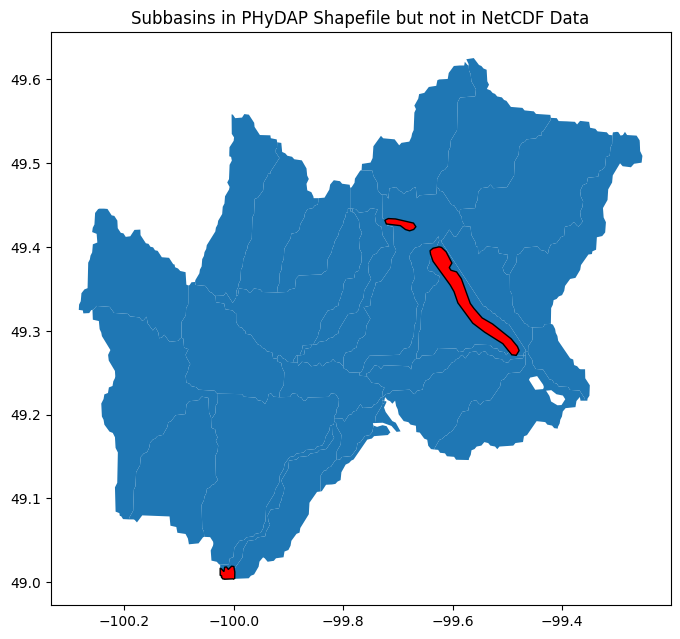

In [14]:
nc_ids = set(extracted_data["HYBAS_ID"].data)
shp_ids = set(basins_hybas_ids)

missing_ids = list(shp_ids - nc_ids)
print("Missing HYBAS_IDs:", missing_ids)

# All intersecting basins
intersecting = phydap_shp[phydap_shp["HYBAS_ID"].isin(basins_hybas_ids)]

# Missing ones
missing = phydap_shp[phydap_shp["HYBAS_ID"].isin(missing_ids)]

fig, ax = plt.subplots(figsize=(8, 8))

# Plot all intersecting basins (light gray)
intersecting.plot(ax=ax)

# Overlay missing basins (no color specified, defaults will distinguish them)
missing.plot(ax=ax, color='red', edgecolor='black')

plt.title("Subbasins in PHyDAP Shapefile but not in NetCDF Data")
plt.show()

IY (2026-03-31) 

For Pembina river, the netCDF file is missing 3 subbasins that are present in the phydap shapefile that intersect with the pembina watershed. These subbasins were visually inspected in the previous code block. Since they were small enough to be negligible, we can just drop them.

**Do not run this if the number of HYBAS_IDs is the same as the number of subbasins in the netCDF file**

In [15]:
phydap_shp = phydap_shp[
    phydap_shp["HYBAS_ID"].isin(nc_ids)
]

# sanity check (should be true!)
set(phydap_shp["HYBAS_ID"]) == set(nc_ids)

True

In [16]:
# Construct a longitude-like axis representing basin IDs for the selected basins of interest
londim_vals = extracted_data["HYBAS_ID"].data[basins_of_interest].astype(np.float64)


In [17]:
# Build a mapping table that connects grid indices to HYBAS_IDs
hybas_map = pd.DataFrame({
    "grid_idx": range(len(londim_vals)),
    "hybas_id": londim_vals
})
hybas_map.to_csv(NC_PROCESSED_PATH + "hybas_map.csv", index=False)

In [18]:
# Specify new dimensions (using custom phydap_dim class)
time_dim = phydap.phydap_dim('time', 'hours since 1900-01-01 00:00:00', extracted_data['nt'], 'T',  extracted_data['var_data'])
lon_dim = phydap.phydap_dim('lon', 'degrees_east', len(basins_of_interest), 'X', extracted_data['HYBAS_ID'][basins_of_interest])

In [19]:
runoff_data = phydap.phydap_var('runoff', var_units, extracted_data['reshaped'][:,:,basins_of_interest])

### 3.3 Generate new .nc file with latitude dimension

In [20]:
# Define NetCDF output
new_file_name = input('Enter the desired output file name (without .nc extension): ')
output_path = path_out + new_file_name + '.nc'

In [21]:
lat_dim = phydap.phydap_dim('lat', 'degrees_north', extracted_data['nlat'], 'Y', extracted_data['lat']) # Create false latitude dimension

In [22]:
phydap.save_pd_to_nc(output_path, dims_list=[time_dim, lat_dim, lon_dim], var_data=runoff_data)

Saved modified .nc file to c:/Users/iyaktubay/PWA/Data/Pembina/Runoff/Processed/PHyDAP_RDRS21_hourly_runoff_adj.nc
Warning! Need to check that dimensions were properly converted (array is reshaped and can get scrambled).


In [23]:
phydap_raw.nc_close()

Closed file ../Data/Pembina/Runoff/Raw/PHyDAP_RDRS21_hourly_runoff.nc


### 3.4 Quality Check - Ensure that the netCDF file retains shape (no shuffling of data)

TS Note: This test would be more robust if we did a comparison with the original .nc file (not the reshaped data array)

IY reply (2026-03-31): The comparison is already with the original .nc file (extracted_data contains the original .nc file)

In [24]:
expected_dim_order = input('Enter the expected dimension order as a list (e.g., ["time", "lat", "lon"]): ')

# Open the newly created NetCDF file
with Dataset(output_path, 'r') as new_nc:
    # Extract the saved variable (assuming it's called 'runoff')
    new_runoff = new_nc.variables['runoff'][:]
    
    # Check shape equality
    original_shape = extracted_data['reshaped'][:, :, basins_of_interest].shape
    new_shape = new_runoff.shape
    
    print("Original shape:", original_shape)
    print("New shape:", new_shape)
    if original_shape == new_shape:
        print("Shape matches (good).")
    else:
        print("Shape mismatch (bad)!")

    # Check dimension order
    print("Original dim order:", list(new_nc.variables['runoff'].dimensions))
    print(f"Expected dim order: {expected_dim_order}") 
    
    # Check coordinate order (first and last values)
    orig_lon = extracted_data['HYBAS_ID'][basins_of_interest]
    new_lon = new_nc.variables['lon'][:]
    if np.array_equal(orig_lon, new_lon):
        print("Longitude order matches (good).")
    else:
        print("Longitude order mismatch (bad)!")

    # Ensure no NaNs or unexpected changes
    if np.array_equal(
        extracted_data['reshaped'][:, :, basins_of_interest],
        new_runoff
    ):
        print("Data identical (good).")
    else:
        print("Data content differs (bad, check for rounding or precision changes)")

Original shape: (341760, 1, 28)
New shape: (341760, 1, 28)
Shape matches (good).
Original dim order: ['time', 'lat', 'lon']
Expected dim order: ["time",  
Longitude order matches (good).
Data identical (good).


## 4. Generate GridWeights.txt file from PHyDAP shapefile

### 4.1 Load data from hydrofabric and PHyDAP shapefiles

In [25]:
# Read the PHyDAP shapefile
# phydap_shp = gpd.read_file(path_in_phydap_shp) # IY: I commented this out for Pembina. Uncomment for other watersheds where this is needed.

# Read the depression depths shapefile
deps_shp = gpd.read_file(path_in_deps_shp + ".shp")

deps_shp = deps_shp[deps_shp["Lake_Cat"] <2]

print("PHyDAP columns:", phydap_shp.columns)
print("Depression depths columns:", deps_shp.columns)
print("PHyDAP CRS:", phydap_shp.crs)
print("Deps CRS:", deps_shp.crs)


PHyDAP columns: Index(['HYBAS_ID', 'geometry'], dtype='object')
Depression depths columns: Index(['SubId', 'DowSubId', 'RivSlope', 'RivLength', 'BasSlope', 'BasAspect',
       'BasArea', 'BkfWidth', 'BkfDepth', 'Lake_Cat', 'HyLakeId', 'LakeVol',
       'LakeDepth', 'LakeArea', 'Laketype', 'Has_POI', 'MeanElev', 'FloodP_n',
       'Q_Mean', 'Ch_n', 'DrainArea', 'Strahler', 'Seg_ID', 'Seg_order',
       'Max_DEM', 'Min_DEM', 'Obs_NM', 'SRC_obs', 'centroid_x', 'centroid_y',
       'DA_Chn_L', 'DA_Slope', 'DA_Chn_Slp', 'outletLat', 'outletLng', 'k',
       'c', 'SSDA_NM', 'SDA_NM', 'Deps_Depth', 'Deps_Vol_m', 'geometry'],
      dtype='object')
PHyDAP CRS: EPSG:4326
Deps CRS: EPSG:3158


### 4.2 Map PHyDAP to hydrofabric subbasin IDs

Centroids inside PHyDAP: 196
Centroids outside PHyDAP: 4
Outside centroids SubIds:
[310017072, 310017092, 310018489, 310019568]
Joined shape: (200, 4)
Number of matches: 196
Unique HYBAS_IDs: 19


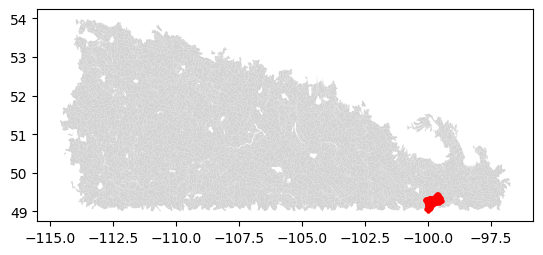

In [26]:
# Create GridWeights.txt file based on where deps hydrofabric centroids fall in the PHyDAP file

# Load grid indices map from PHyDAP processing
hybas_map = pd.read_csv(NC_PROCESSED_PATH + r"hybas_map.csv")

# Filter out invalid geometries
phydap_shp = phydap_shp[phydap_shp.geometry.is_valid & ~phydap_shp.geometry.is_empty].copy()

# Ensure deps hydrofabric is the same CRS as PHyDAP
deps_shp = deps_shp.to_crs(phydap_shp.crs)

# Find centroids for deps hydrofabric subbasins
# deps_shp['centroid'] = deps_shp.geometry.centroid
deps_shp['centroid'] = deps_shp.representative_point()

# Load centroids point data into geodataframe
centroids_gdf = gpd.GeoDataFrame(deps_shp[['SubId']], 
                                 geometry=deps_shp['centroid'], 
                                 crs=deps_shp.crs)

# Spatial join to find which centroids are inside PHyDAP polygons
inside = gpd.sjoin(centroids_gdf, phydap_shp, how='inner', predicate='within')
outside = centroids_gdf[~centroids_gdf['SubId'].isin(inside['SubId'])]

print(f"Centroids inside PHyDAP: {len(inside)}")
print(f"Centroids outside PHyDAP: {len(outside)}")

if len(outside) > 0:
    print("Outside centroids SubIds:")
    print(outside['SubId'].to_list())

    # Optional: save for visualization or debugging
    outside.to_file("outside_centroids.shp")

# Join subbasin IDs based on centroid location
joined = gpd.sjoin(centroids_gdf, phydap_shp, how='left', predicate='within')
mapping_df = joined[['SubId', 'HYBAS_ID']]

print("Joined shape:", joined.shape)
print("Number of matches:", joined['HYBAS_ID'].notna().sum())
print("Unique HYBAS_IDs:", joined['HYBAS_ID'].nunique())

# Quick visual check
phydap_shp.plot(color='lightgray')
centroids_gdf.plot(ax=plt.gca(), color='red', markersize=5)
plt.show()


In [27]:
# Check if any data points are left blank
missing = mapping_df[mapping_df['HYBAS_ID'].isna()]

# For any centroids that do not fall inside a PHyDAP subbasin, take nearest subbasin
if len(missing) > 0:
    print(f"Finding nearest PHyDAP subbasin for centroids falling outside of PHyDAP range ({len(missing)})...")

    # Convert PHyDAP polygons to centroids to speed up distance computation
    # Only keep PHyDAP basins that exist in NetCDF
    valid_phydap = phydap_shp[
        phydap_shp['HYBAS_ID'].isin(hybas_map['hybas_id'])
    ].copy()

    # Convert to centroids
    phydap_centroids = valid_phydap.copy()
    phydap_centroids['centroid'] = phydap_centroids.geometry.centroid
    phydap_centroids = phydap_centroids.set_geometry('centroid')
    
    # Remove any invalid centroids (unlikely, but just to be safe)
    phydap_centroids = phydap_centroids[phydap_centroids.geometry.notna()].copy()

    # Create list to store additional mappings
    nearest_matches = []

    # Loop through each unmatched point
    for idx, row in centroids_gdf[centroids_gdf['SubId'].isin(missing['SubId'])].iterrows():
        centroid_geom = row.geometry

        # Compute distances to all PHyDAP centroids
        phydap_centroids['distance'] = phydap_centroids.distance(centroid_geom)
        nearest_phydap = phydap_centroids.loc[phydap_centroids['distance'].idxmin()]

        # Store the match (SubId, nearest HYBAS_ID)
        nearest_matches.append({'SubId': row['SubId'], 'HYBAS_ID': nearest_phydap['HYBAS_ID']})

    # Convert to DataFrame and append to main mapping_df
    nearest_df = gpd.GeoDataFrame(nearest_matches)
    mapping_df = mapping_df[~mapping_df['HYBAS_ID'].isna()].copy()
    mapping_df = pd.concat([mapping_df, nearest_df], ignore_index=True)
    
    # Make sure types match
    mapping_df['HYBAS_ID'] = mapping_df['HYBAS_ID'].astype(int)
    hybas_map['hybas_id'] = hybas_map['hybas_id'].astype(int)

    # Drop unwanted duplicate columns before merging
    mapping_df = mapping_df[['SubId', 'HYBAS_ID']].copy()
    hybas_map = hybas_map[['hybas_id', 'grid_idx']].copy()

    # Merge cleanly
    mapping_df = mapping_df.merge(
        hybas_map,
        left_on='HYBAS_ID',
        right_on='hybas_id',
        how='left'
    ).drop(columns=['hybas_id'])

# Check that no subids are mapped to the same hybasid
dup_check = mapping_df.duplicated(subset='SubId', keep=False)
if dup_check.any():
    print(f"Warning: {dup_check.sum()} duplicate SubIds found after nearest matching.")

# Write to CSV (not needed but good to have)
mapping_df.to_csv(NC_INTERIM_PATH + "subid_to_phydap_mapping.csv", index=False)


Finding nearest PHyDAP subbasin for centroids falling outside of PHyDAP range (4)...


C:\Users\iyaktubay\AppData\Local\Temp\ipykernel_8200\906363801.py:16: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  phydap_centroids['centroid'] = phydap_centroids.geometry.centroid
C:\Users\iyaktubay\AppData\Local\Temp\ipykernel_8200\906363801.py:30: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  phydap_centroids['distance'] = phydap_centroids.distance(centroid_geom)
C:\Users\iyaktubay\AppData\Local\Temp\ipykernel_8200\906363801.py:30: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  phydap_centroids['distance'] = phydap_centroids.distance(centroid_geom)
C:\Users\iyaktubay\

In [28]:
print("HRUs:", len(mapping_df))
print("Unique grid_idx:", mapping_df['grid_idx'].nunique())
print("Max grid_idx:", mapping_df['grid_idx'].max())

HRUs: 200
Unique grid_idx: 19
Max grid_idx: 24


### 4.3 Generate and output GridWeights.txt file

In [29]:
output_path = NC_PROCESSED_PATH + r"GridWeights.txt"

with open(output_path, 'w') as file:
    file.write(
        f"# ----------------------------------------------\n"
        f"# Raven Input file\n"
        f"# {WATERSHED_NAME}\n"
        f"# ----------------------------------------------\n\n"
        f":GridWeights\n"
        f"   #\n"
        f"   # [# HRUs]\n"
        f"   :NumberHRUs       {len(mapping_df)}\n"
        f"   :NumberGridCells  {len(basins_of_interest)}\n"
        f"   #\n"
        f"   # [HRU ID] [Cell #] [w_kl]"
    )
    
    for _, row in mapping_df.iterrows():
        file.write(f"\n  {int(row['SubId']):>10} {int(row['grid_idx']):>10}{1.0:>10.3f}")
    
    file.write("\n:EndGridWeights")

## 5. Time offsets

Alternate workflow for extracting specific PHyDAP datasets (not for standard Raven calibration flow)

In [ ]:
# Create copy of the clipped .nc with new latitude dimension
old_file_name = input('Enter the name of the clipped .nc file (with .nc extension): ')
old_file_path = NC_PROCESSED_PATH + old_file_name
new_file_name = input('Enter the desired output file name (with .nc extension): ')
new_file_path = NC_PROCESSED_PATH + new_file_name

In [ ]:
phydap.time_offset(old_file_path, new_file_path, offset=10)

In [ ]:
# # Testing the function
# rdrs_clipped = phydap.phydap_nc(filepath = new_file_path, var_name='runoff', file_setting='r+')
# print(rdrs_clipped.file.variables['time'][:10])
# rdrs_clipped.nc_close()

### Old Code: Generate and plot timeseries from PHyDAP nc files

In [ ]:

# cypress_runoff = phydap_runoff['reshaped'][:,0,317]
# cypress_rainfall = extract_phydap(input_file=(NC_RAW_PATH + '/PHyDAP_RDRS21_hourly_rainfall.nc'), var_name='rainfall')['reshaped'][:,0,317]
# phydap_snowmelt = extract_phydap(input_file=(NC_RAW_PATH + '/PHyDAP_RDRS21_hourly_snowmelt.nc'), var_name='snowmelt')
# cypress_snowmelt = phydap_snowmelt['reshaped'][:,0,317]
# timestamps = phydap_snowmelt['var_data']
# HYBAS_ID = phydap_snowmelt['HYBAS_ID']

In [ ]:
# Export a subset of the data to csv
# pd.DataFrame({'time_hrs_since_1900': var_data, 'precip': reshaped[:,0,317].data}).to_csv(path_out + '/rainfall_time_series_317.csv', index=False)


In [ ]:
# Plot a sample runoff graph


# cypress_data = pd.DataFrame({'timestamp': ts, 'rainfall': cypress_rainfall, 'snowmelt': cypress_snowmelt, 'runoff': cypress_runoff})

In [ ]:
# Export the data to csv

# cypress_data.to_csv(NC_PROCESSED_PATH + '/cypress_rainfall_snowmelt_runoff_317.csv', index=False)

In [ ]:
# Plot a sample runoff graph

# plot_df = cypress_data[203500:203600]
# plt.plot(plot_df['timestamp'], plot_df['runoff'])
# plt.plot(plot_df['timestamp'], plot_df['rainfall'])
# plt.plot(plot_df['timestamp'], plot_df['snowmelt'])
# plt.xlabel('Time (hours since 1900-01-01 00:00:00)')

In [ ]:
## Second quality check

# print(np.where(subset == max_val))

# reshaped.shape

## 3.2 Visualize timeseries before writing to new file

In [ ]:
ts = phydap_runoff['var_data'] - 60  # Apply a 60 hour offset to time data

In [ ]:
import matplotlib.pyplot as plt

# Suppose you want to plot for basin_id = 123456
basin_id = 308
# idx = np.where(HYBAS_ID == basin_id)[0][0]  # Find index of basin_id

idx = 0 # testing for first subbasin in dataset

# Plot timeseries for that basin (assuming nlat=1)
plt.figure(figsize=(12, 6))
plt.plot(timestamps[220000:221900], subset[220000:221900, 0, idx])
plt.xlabel("Time (hours)")
plt.ylabel("Runoff (mm/h)")
plt.title(f"Runoff timeseries for HYBAS_ID {basin_id}")
plt.tight_layout()
plt.show()

In [ ]:
var_data = phydap_runoff['var_data'] - 60  # Apply a 60 hour offset to time data

In [ ]:

# # Define dimensions
# ncout.createDimension("lon", len(basins_of_interest))
# ncout.createDimension("lat", 1)
# ncout.createDimension("time", phydap_runoff['nt'])


# # Create and assign dimension variables
# lon_var = ncout.createVariable("lon", "f8", ("lon",))
# lon_var.units = "degrees_east"
# lon_var.axis = "X"
# lon_var[:] = londim_vals

# lat_var = ncout.createVariable("lat", "f8", ("lat",))
# lat_var.units = "degrees_north"
# lat_var.axis = "Y"
# lat_var[:] = phydap_runoff['lat'].astype(np.float64)

# time_var = ncout.createVariable("time", "f8", ("time",))
# time_var.units = "hours since 1900-01-01 00:00:00"
# time_var.axis = "T"
# time_var[:] = var_data.astype(np.float64)

In [ ]:
phydap_raw.nc_close()

In [ ]:
# # Define runoff variable
# fillvalue = 1e32
# runoff_var = ncout.createVariable("runoff", "f4", ("time", "lat", "lon"), fill_value=fillvalue)
# runoff_var.long_name = "runoff"
# runoff_var.units = var_units


# # Write runoff data, in chunks if large
# if subset.size < 2**31 - 1:
#     runoff_var[:, :, :] = subset
# else:
#     for period in range(nt // 100000 + 1):
#         start = period * 100000
#         end = min(nt, (period + 1) * 100000)
#         runoff_var[:, :, start:end] = subset[:, :, start:end]


# # Finalize
# ncout.sync()
# ncout.close()
# print(f"New file written to: {output_path}")

## 4. Explore output data to ensure everything looks good (optional)

In [ ]:
# Open the NetCDF file
output_path = "../Data/Cypress_New/Runoff/Processed/lib_test.nc"

ds = Dataset(output_path, mode="r")

print(ds)                        # Print summary
print(ds.variables.keys())      # List of variable names
print(ds.dimensions.keys())     # List of dimensions

# Check variable attributes
print(ds.variables['cropped_runoff'].long_name)
print(ds.variables['cropped_runoff'].units)
print(ds.variables['time'].units)


In [ ]:
runoff = ds.variables['cropped_runoff'][:10000, 0, :]  # shape: (lon, lat, time)
print("Runoff shape:", runoff.shape)

lon = ds.variables['lon'][:]
lat = ds.variables['lat'][:]
time = ds.variables['time'][:]

print("lon count:", len(lon))
print("lat count:", len(lat))
print("time count:", len(time))

In [ ]:
# Overall stats
print("Runoff (mm/h):")
print("  Mean:", np.mean(runoff))
print("  Min:", np.min(runoff))
print("  Max:", np.max(runoff))

In [ ]:
import matplotlib.pyplot as plt

plt.plot(time[:10000], runoff[:,4100])

In [ ]:
# Average over time for each basin
mean_per_basin = np.mean(runoff, axis=0).data.flatten()  # shape: (lon,) if lat = 


# Create DataFrame of HYBAS_ID and mean runoff
df = pd.DataFrame({
    "HYBAS_ID": lon.astype(int),
    "mean_runoff_mm_per_hr": mean_per_basin
})

df.to_csv(path_out + "/mean_runoff_per_basin.csv", index=False)
print("Exported basin-level runoff summary.")


In [ ]:
ds.close()

In [ ]:
(time[10000] % (24*365.25)) / 24

## Testing files